# Visualize YOLO Dataset Statistics

This notebook reads the CSV file with YOLO annotations and visualizes various statistics:
- Camera height distribution
- Bounding box area distribution
- Bounding box area distribution per camera height
- 2D histogram: bbox distribution vs position distance from frame center

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [11]:
# Load the CSV file
CSV_FILE = "yolo_annotations.csv"

df = pd.read_csv(CSV_FILE)
print(f"Loaded {len(df)} annotations")
print(f"\nColumns: {list(df.columns)}")
df.head()

Loaded 31252 annotations

Columns: ['filename', 'x', 'y', 'w', 'h', 'pos_x', 'pos_y', 'cam_height', 'subset']


,filename,x,y,w,h,pos_x,pos_y,cam_height,subset
0,4.2_batch7____4.2_H_cam_289_menivimOS_31.txt,0.669141,0.578896,0.171094,0.219708,0.583594,0.469042,290,train
1,4.2_batch7____4.2_H_cam_289_menivimOS_31.txt,0.349453,0.726865,0.166719,0.220396,0.266094,0.616667,290,train
2,4.2_batch6____4.2_H_cam_330_spacesOS_136.txt,0.924188,0.329885,0.151625,0.146021,0.848375,0.256875,330,train
3,4.2_batch6____4.2_H_cam_330_spacesOS_136.txt,0.762734,0.706562,0.120156,0.196458,0.702656,0.608333,330,train
4,4.2_batch6____4.2_H_cam_330_spacesOS_110.txt,0.367031,0.320104,0.193125,0.212708,0.270469,0.213750,330,train


In [12]:
# Calculate bbox area (normalized coordinates)
df['bbox_area'] = df['w'] * df['h']

# Calculate bbox aspect ratio (width / height)
df['aspect_ratio'] = df['w'] / df['h']

# Calculate distance from center (normalized coordinates)
# Center is at (0.5, 0.5) in normalized YOLO format
df['dist_from_center_x'] = df['x'] - 0.5
df['dist_from_center_y'] = df['y'] - 0.5
df['dist_from_center'] = np.sqrt(df['dist_from_center_x']**2 + df['dist_from_center_y']**2)

print(f"Added computed columns: bbox_area, aspect_ratio, dist_from_center")
print(f"\nBbox area stats:")
print(df['bbox_area'].describe())
print(f"\nAspect ratio stats:")
print(df['aspect_ratio'].describe())

Added computed columns: bbox_area, aspect_ratio, dist_from_center

Bbox area stats:
count    31252.000000
mean         0.042517
std          0.017948
min          0.000708
25%          0.029380
50%          0.039666
75%          0.052174
max          0.186066
Name: bbox_area, dtype: float64

Aspect ratio stats:
count    31252.000000
mean         0.863567
std          0.290249
min          0.236057
25%          0.653410
50%          0.809636
75%          1.027219
max          2.778215
Name: aspect_ratio, dtype: float64


## 1. Camera Height Distribution

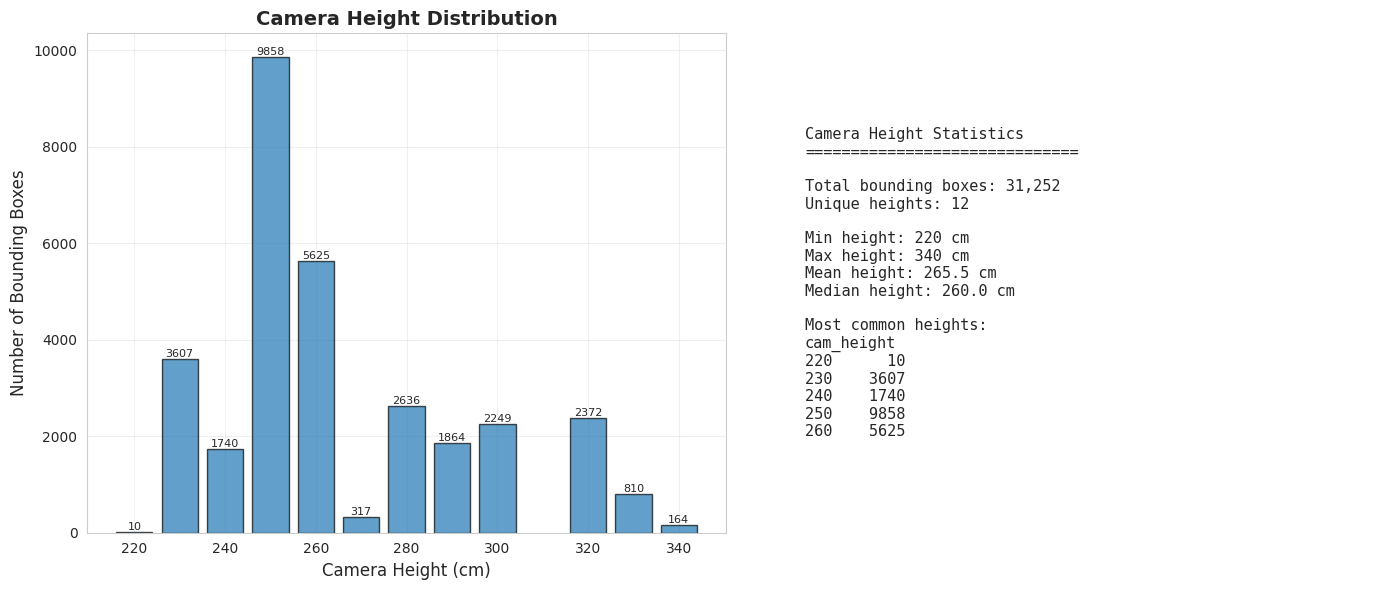


Camera height distribution by subset:
              count        mean        std    min    25%    50%    75%    max
subset                                                                       
holdout       407.0  263.906634  26.330995  220.0  230.0  270.0  290.0  300.0
holdout_v2    609.0  262.610837  23.888060  220.0  230.0  270.0  270.0  300.0
train       27192.0  265.688070  27.805049  230.0  250.0  260.0  280.0  340.0
val          3044.0  264.622208  27.243052  230.0  250.0  250.0  280.0  340.0


In [13]:
plt.figure(figsize=(14, 6))

# Histogram
plt.subplot(1, 2, 1)
height_counts = df['cam_height'].value_counts().sort_index()
plt.bar(height_counts.index, height_counts.values, width=8, edgecolor='black', alpha=0.7)
plt.xlabel('Camera Height (cm)', fontsize=12)
plt.ylabel('Number of Bounding Boxes', fontsize=12)
plt.title('Camera Height Distribution', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

# Add value labels on top of bars
for idx, val in zip(height_counts.index, height_counts.values):
    if val > 0:
        plt.text(idx, val, str(val), ha='center', va='bottom', fontsize=8)

# Statistics table
plt.subplot(1, 2, 2)
plt.axis('off')
stats_text = f"""
Camera Height Statistics
{'='*30}

Total bounding boxes: {len(df):,}
Unique heights: {df['cam_height'].nunique()}

Min height: {df['cam_height'].min()} cm
Max height: {df['cam_height'].max()} cm
Mean height: {df['cam_height'].mean():.1f} cm
Median height: {df['cam_height'].median():.1f} cm

Most common heights:
{height_counts.head(5).to_string()}
"""
plt.text(0.1, 0.5, stats_text, fontsize=11, family='monospace', 
         verticalalignment='center')

plt.tight_layout()
plt.savefig('camera_height_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nCamera height distribution by subset:")
print(df.groupby('subset')['cam_height'].describe())

## 2. Bounding Box Area Distribution (Overlay)

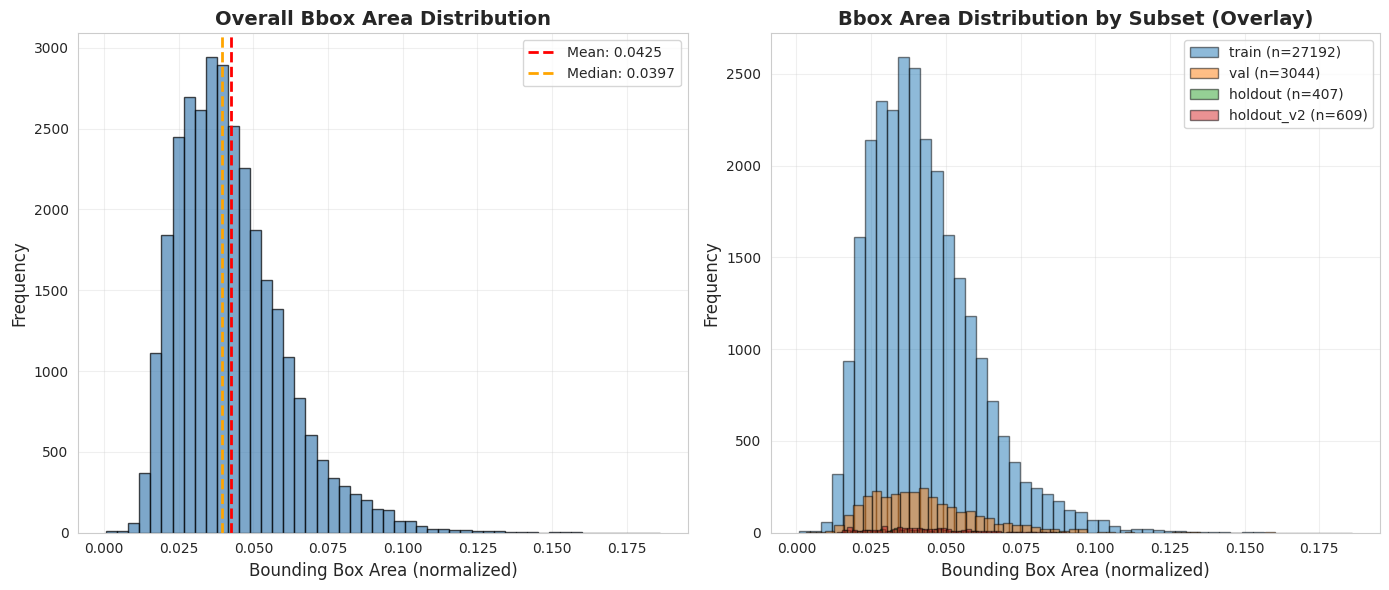


Bbox area statistics:
count    31252.000000
mean         0.042517
std          0.017948
min          0.000708
25%          0.029380
50%          0.039666
75%          0.052174
max          0.186066
Name: bbox_area, dtype: float64


In [14]:
plt.figure(figsize=(14, 6))

# Overall distribution
plt.subplot(1, 2, 1)
plt.hist(df['bbox_area'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
plt.xlabel('Bounding Box Area (normalized)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Overall Bbox Area Distribution', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

# Add statistics
mean_area = df['bbox_area'].mean()
median_area = df['bbox_area'].median()
plt.axvline(mean_area, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_area:.4f}')
plt.axvline(median_area, color='orange', linestyle='--', linewidth=2, label=f'Median: {median_area:.4f}')
plt.legend()

# Distribution by subset (overlay)
plt.subplot(1, 2, 2)
for subset in df['subset'].unique():
    subset_data = df[df['subset'] == subset]['bbox_area']
    plt.hist(subset_data, bins=50, alpha=0.5, label=f'{subset} (n={len(subset_data)})', edgecolor='black')

plt.xlabel('Bounding Box Area (normalized)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Bbox Area Distribution by Subset (Overlay)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bbox_area_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nBbox area statistics:")
print(df['bbox_area'].describe())

## 3. Bounding Box Area Distribution per Camera Height (Box Plot)

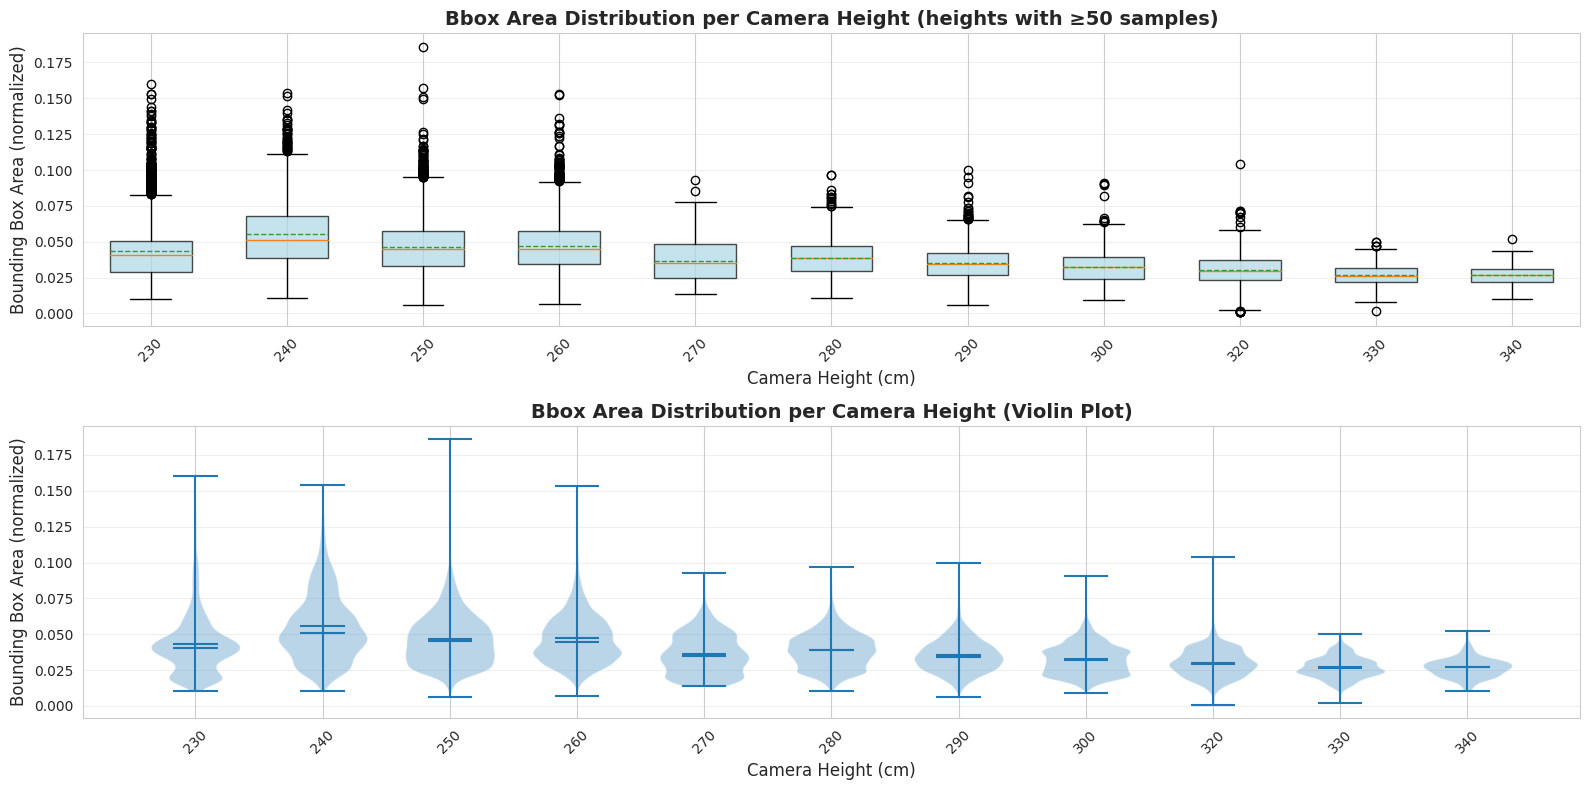


Bbox area statistics per camera height:

Height 230 cm (n=3607):
  Mean: 0.0433
  Median: 0.0407
  Std: 0.0208

Height 240 cm (n=1740):
  Mean: 0.0554
  Median: 0.0509
  Std: 0.0236

Height 250 cm (n=9858):
  Mean: 0.0467
  Median: 0.0450
  Std: 0.0177

Height 260 cm (n=5625):
  Mean: 0.0471
  Median: 0.0448
  Std: 0.0171

Height 270 cm (n=317):
  Mean: 0.0363
  Median: 0.0349
  Std: 0.0142

Height 280 cm (n=2636):
  Mean: 0.0389
  Median: 0.0387
  Std: 0.0124

Height 290 cm (n=1864):
  Mean: 0.0352
  Median: 0.0342
  Std: 0.0113

Height 300 cm (n=2249):
  Mean: 0.0326
  Median: 0.0320
  Std: 0.0107

Height 320 cm (n=2372):
  Mean: 0.0301
  Median: 0.0296
  Std: 0.0100

Height 330 cm (n=810):
  Mean: 0.0270
  Median: 0.0263
  Std: 0.0074

Height 340 cm (n=164):
  Mean: 0.0268
  Median: 0.0268
  Std: 0.0067


In [15]:
# Prepare data for box plot - only heights with sufficient data
height_counts = df['cam_height'].value_counts()
min_samples = 50  # Minimum number of samples to include in box plot
valid_heights = height_counts[height_counts >= min_samples].index.sort_values()

df_filtered = df[df['cam_height'].isin(valid_heights)]

plt.figure(figsize=(16, 8))

# Box plot
plt.subplot(2, 1, 1)
positions = range(len(valid_heights))
box_data = [df_filtered[df_filtered['cam_height'] == h]['bbox_area'].values for h in valid_heights]

bp = plt.boxplot(box_data, positions=positions, widths=0.6, patch_artist=True,
                 showmeans=True, meanline=True)

# Color boxes
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
    patch.set_alpha(0.7)

plt.xticks(positions, valid_heights, rotation=45)
plt.xlabel('Camera Height (cm)', fontsize=12)
plt.ylabel('Bounding Box Area (normalized)', fontsize=12)
plt.title(f'Bbox Area Distribution per Camera Height (heights with ≥{min_samples} samples)', 
          fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')

# Violin plot (alternative visualization)
plt.subplot(2, 1, 2)
parts = plt.violinplot(box_data, positions=positions, widths=0.7, 
                       showmeans=True, showmedians=True)

plt.xticks(positions, valid_heights, rotation=45)
plt.xlabel('Camera Height (cm)', fontsize=12)
plt.ylabel('Bounding Box Area (normalized)', fontsize=12)
plt.title('Bbox Area Distribution per Camera Height (Violin Plot)', 
          fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('bbox_area_per_height.png', dpi=150, bbox_inches='tight')
plt.show()

# Print statistics per height
print("\nBbox area statistics per camera height:")
for height in valid_heights:
    height_data = df_filtered[df_filtered['cam_height'] == height]['bbox_area']
    print(f"\nHeight {height} cm (n={len(height_data)}):")
    print(f"  Mean: {height_data.mean():.4f}")
    print(f"  Median: {height_data.median():.4f}")
    print(f"  Std: {height_data.std():.4f}")

## 3B. Bounding Box Aspect Ratio Distribution (Overlay)

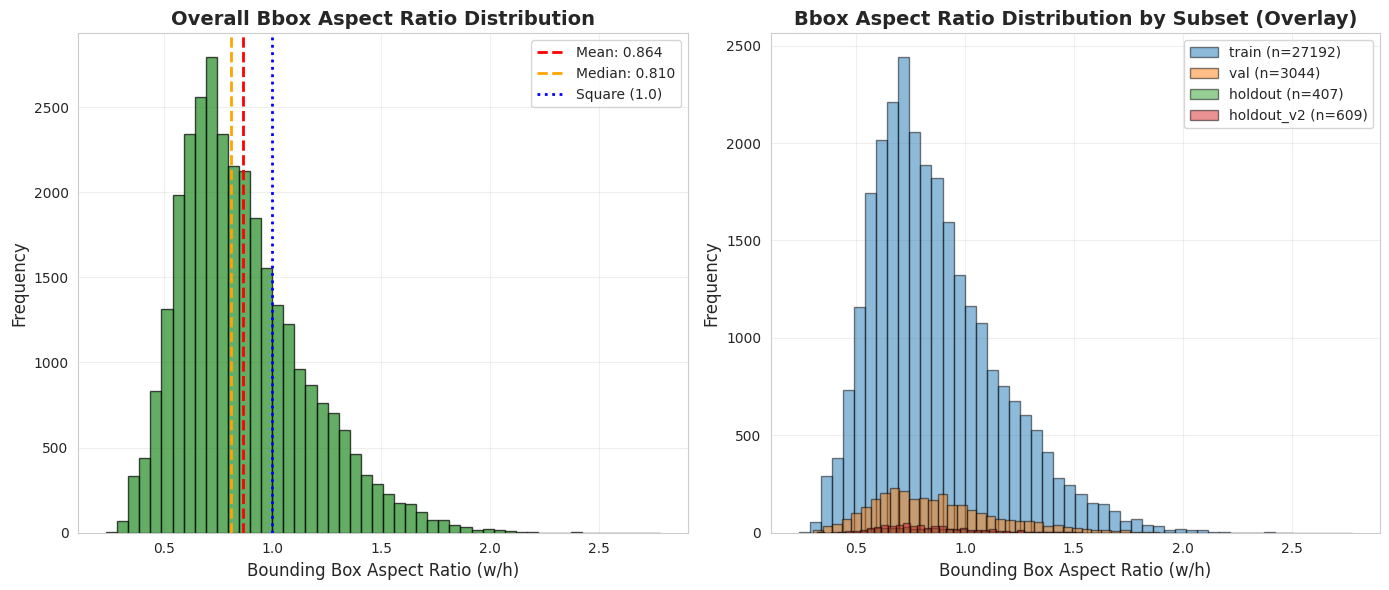


Bbox aspect ratio statistics:
count    31252.000000
mean         0.863567
std          0.290249
min          0.236057
25%          0.653410
50%          0.809636
75%          1.027219
max          2.778215
Name: aspect_ratio, dtype: float64

Aspect ratios > 1 (wider than tall): 8522 (27.27%)
Aspect ratios < 1 (taller than wide): 22728 (72.72%)
Aspect ratios = 1 (square): 2


In [16]:
plt.figure(figsize=(14, 6))

# Overall distribution
plt.subplot(1, 2, 1)
plt.hist(df['aspect_ratio'], bins=50, edgecolor='black', alpha=0.7, color='forestgreen')
plt.xlabel('Bounding Box Aspect Ratio (w/h)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Overall Bbox Aspect Ratio Distribution', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

# Add statistics
mean_ratio = df['aspect_ratio'].mean()
median_ratio = df['aspect_ratio'].median()
plt.axvline(mean_ratio, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_ratio:.3f}')
plt.axvline(median_ratio, color='orange', linestyle='--', linewidth=2, label=f'Median: {median_ratio:.3f}')
plt.axvline(1.0, color='blue', linestyle=':', linewidth=2, label='Square (1.0)')
plt.legend()

# Distribution by subset (overlay)
plt.subplot(1, 2, 2)
for subset in df['subset'].unique():
    subset_data = df[df['subset'] == subset]['aspect_ratio']
    plt.hist(subset_data, bins=50, alpha=0.5, label=f'{subset} (n={len(subset_data)})', edgecolor='black')

plt.xlabel('Bounding Box Aspect Ratio (w/h)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Bbox Aspect Ratio Distribution by Subset (Overlay)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bbox_aspect_ratio_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nBbox aspect ratio statistics:")
print(df['aspect_ratio'].describe())
print(f"\nAspect ratios > 1 (wider than tall): {(df['aspect_ratio'] > 1).sum()} ({(df['aspect_ratio'] > 1).sum()/len(df)*100:.2f}%)")
print(f"Aspect ratios < 1 (taller than wide): {(df['aspect_ratio'] < 1).sum()} ({(df['aspect_ratio'] < 1).sum()/len(df)*100:.2f}%)")
print(f"Aspect ratios = 1 (square): {(df['aspect_ratio'] == 1).sum()}")

## 3C. Bounding Box Aspect Ratio Distribution per Camera Height (Box Plot)

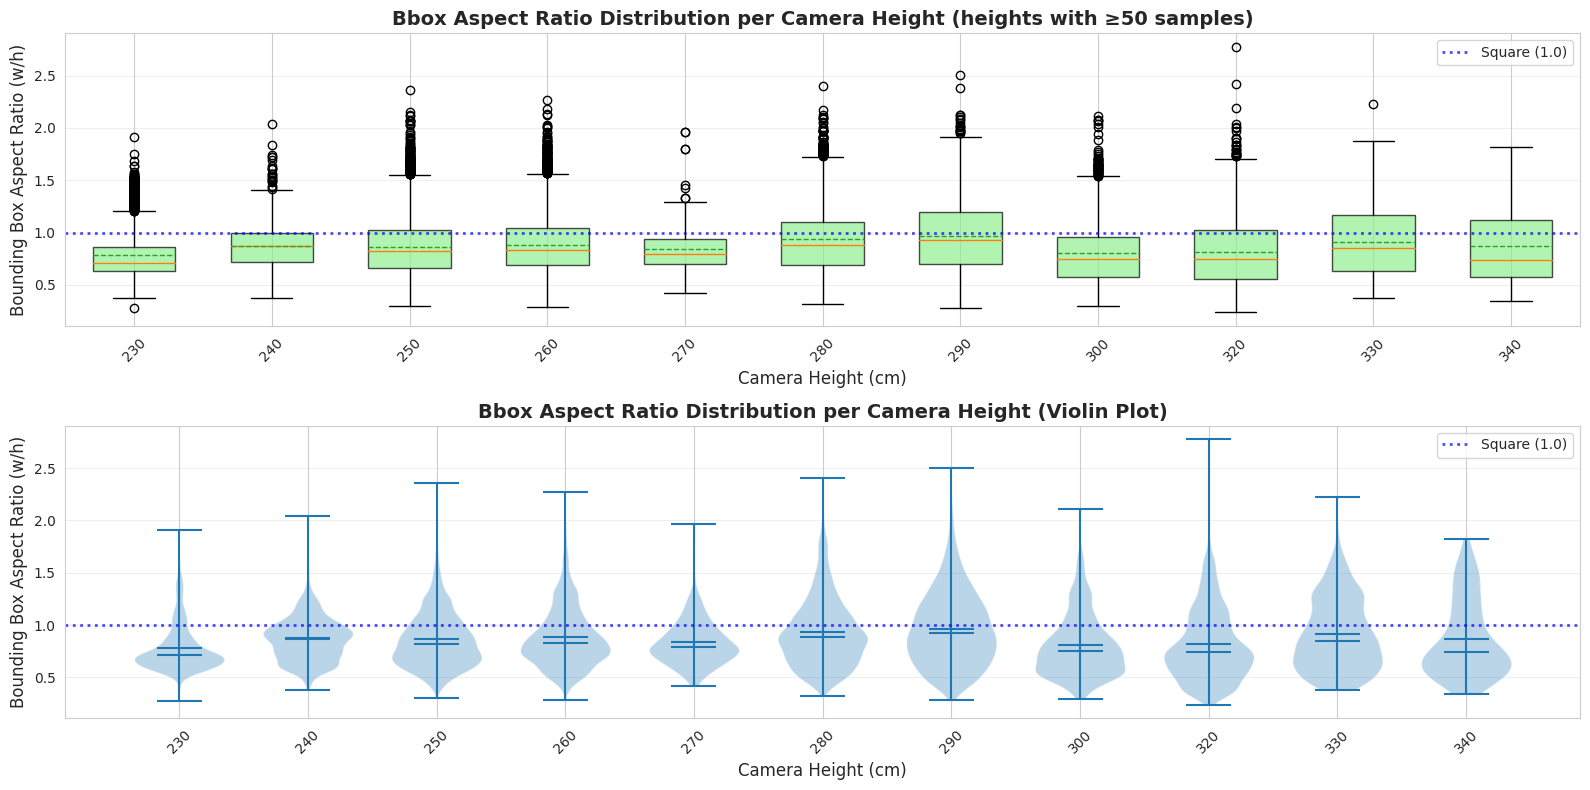


Bbox aspect ratio statistics per camera height:

Height 230 cm (n=3607):
  Mean: 0.7824
  Median: 0.7116
  Std: 0.2232

Height 240 cm (n=1740):
  Mean: 0.8700
  Median: 0.8722
  Std: 0.2140

Height 250 cm (n=9858):
  Mean: 0.8628
  Median: 0.8226
  Std: 0.2668

Height 260 cm (n=5625):
  Mean: 0.8848
  Median: 0.8322
  Std: 0.2860

Height 270 cm (n=317):
  Mean: 0.8391
  Median: 0.7940
  Std: 0.2274

Height 280 cm (n=2636):
  Mean: 0.9344
  Median: 0.8837
  Std: 0.3302

Height 290 cm (n=1864):
  Mean: 0.9657
  Median: 0.9249
  Std: 0.3535

Height 300 cm (n=2249):
  Mean: 0.8087
  Median: 0.7499
  Std: 0.3029

Height 320 cm (n=2372):
  Mean: 0.8148
  Median: 0.7420
  Std: 0.3436

Height 330 cm (n=810):
  Mean: 0.9107
  Median: 0.8511
  Std: 0.3402

Height 340 cm (n=164):
  Mean: 0.8673
  Median: 0.7413
  Std: 0.3671


In [17]:
# Prepare data for box plot - only heights with sufficient data
height_counts = df['cam_height'].value_counts()
min_samples = 50  # Minimum number of samples to include in box plot
valid_heights = height_counts[height_counts >= min_samples].index.sort_values()

df_filtered = df[df['cam_height'].isin(valid_heights)]

plt.figure(figsize=(16, 8))

# Box plot
plt.subplot(2, 1, 1)
positions = range(len(valid_heights))
box_data = [df_filtered[df_filtered['cam_height'] == h]['aspect_ratio'].values for h in valid_heights]

bp = plt.boxplot(box_data, positions=positions, widths=0.6, patch_artist=True,
                 showmeans=True, meanline=True)

# Color boxes
for patch in bp['boxes']:
    patch.set_facecolor('lightgreen')
    patch.set_alpha(0.7)

# Add reference line at aspect ratio = 1 (square)
plt.axhline(y=1.0, color='blue', linestyle=':', linewidth=2, label='Square (1.0)', alpha=0.7)

plt.xticks(positions, valid_heights, rotation=45)
plt.xlabel('Camera Height (cm)', fontsize=12)
plt.ylabel('Bounding Box Aspect Ratio (w/h)', fontsize=12)
plt.title(f'Bbox Aspect Ratio Distribution per Camera Height (heights with ≥{min_samples} samples)', 
          fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3, axis='y')

# Violin plot (alternative visualization)
plt.subplot(2, 1, 2)
parts = plt.violinplot(box_data, positions=positions, widths=0.7, 
                       showmeans=True, showmedians=True)

# Add reference line at aspect ratio = 1 (square)
plt.axhline(y=1.0, color='blue', linestyle=':', linewidth=2, label='Square (1.0)', alpha=0.7)

plt.xticks(positions, valid_heights, rotation=45)
plt.xlabel('Camera Height (cm)', fontsize=12)
plt.ylabel('Bounding Box Aspect Ratio (w/h)', fontsize=12)
plt.title('Bbox Aspect Ratio Distribution per Camera Height (Violin Plot)', 
          fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('bbox_aspect_ratio_per_height.png', dpi=150, bbox_inches='tight')
plt.show()

# Print statistics per height
print("\nBbox aspect ratio statistics per camera height:")
for height in valid_heights:
    height_data = df_filtered[df_filtered['cam_height'] == height]['aspect_ratio']
    print(f"\nHeight {height} cm (n={len(height_data)}):")
    print(f"  Mean: {height_data.mean():.4f}")
    print(f"  Median: {height_data.median():.4f}")
    print(f"  Std: {height_data.std():.4f}")

## 3D. 2D Histogram: Bbox Aspect Ratio vs Position

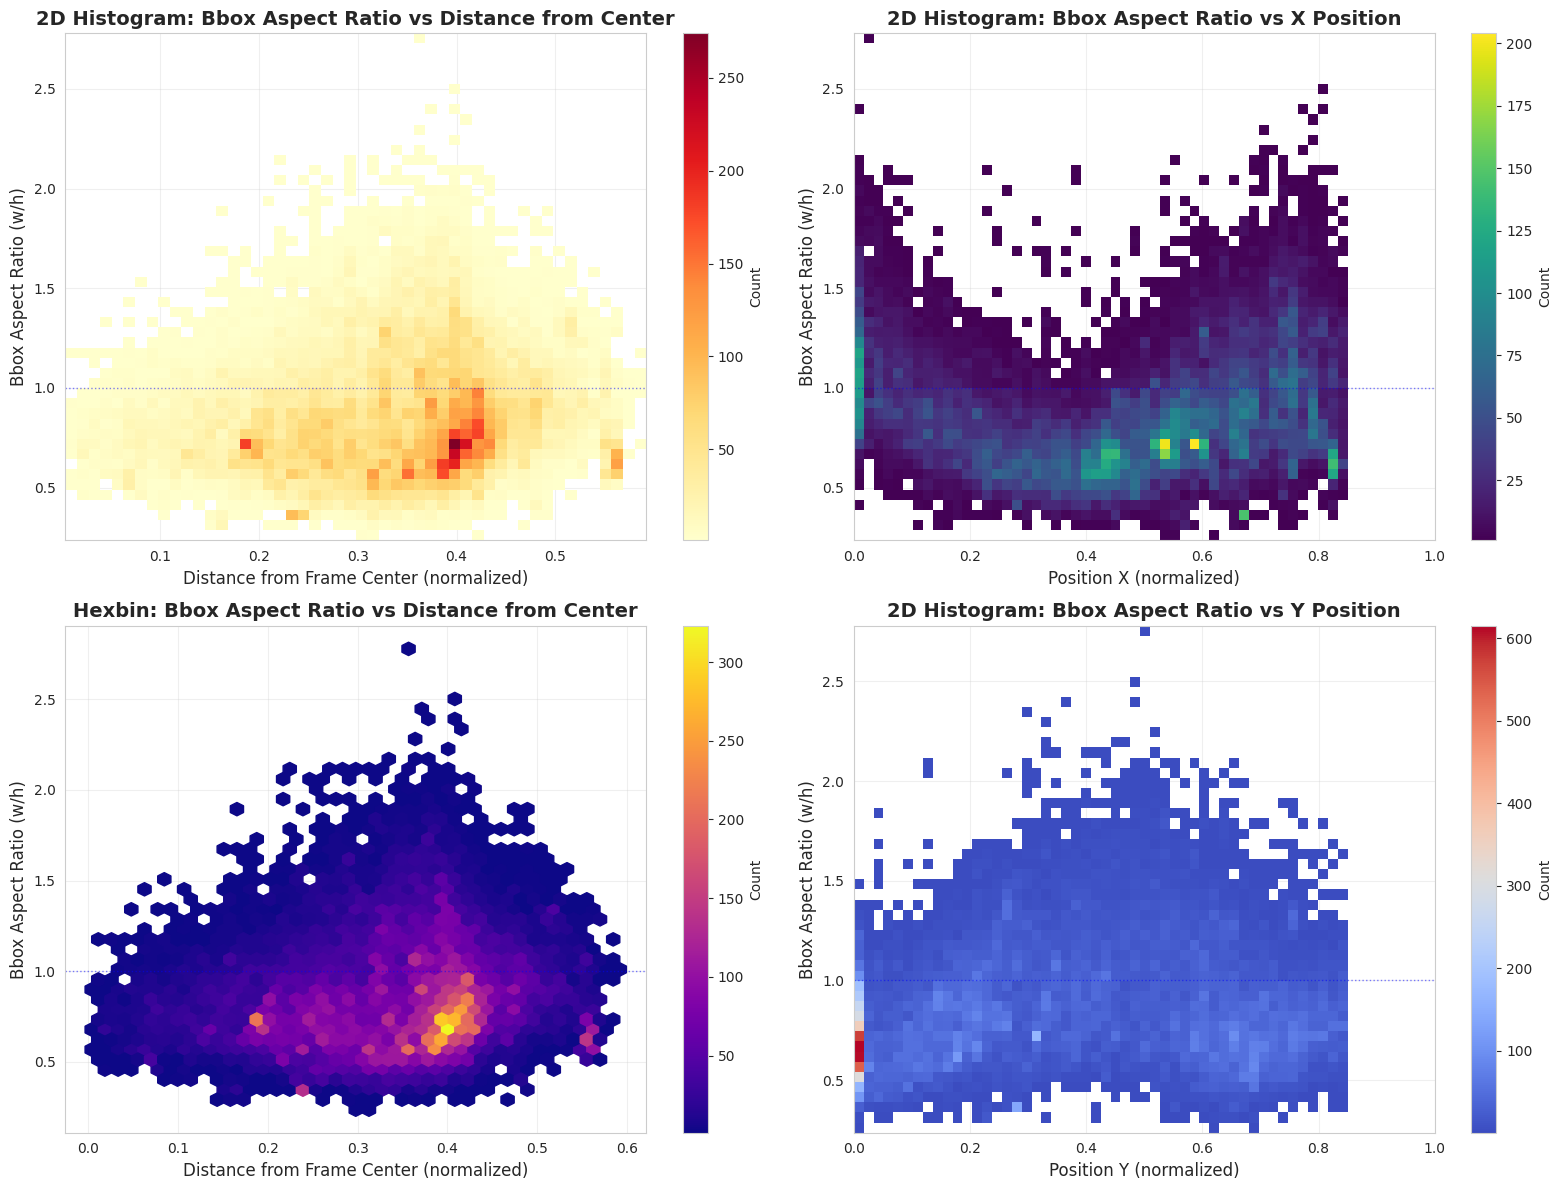

In [18]:
fig = plt.figure(figsize=(16, 12))

# 2D histogram: aspect ratio vs distance from center
plt.subplot(2, 2, 1)
plt.hist2d(df['dist_from_center'], df['aspect_ratio'], bins=50, cmap='YlOrRd', cmin=1)
plt.colorbar(label='Count')
plt.xlabel('Distance from Frame Center (normalized)', fontsize=12)
plt.ylabel('Bbox Aspect Ratio (w/h)', fontsize=12)
plt.title('2D Histogram: Bbox Aspect Ratio vs Distance from Center', fontsize=14, fontweight='bold')
plt.axhline(y=1.0, color='blue', linestyle=':', linewidth=1, alpha=0.5)
plt.grid(True, alpha=0.3)

# 2D histogram: pos_x vs aspect ratio
plt.subplot(2, 2, 2)
plt.hist2d(df['pos_x'], df['aspect_ratio'], bins=50, cmap='viridis', cmin=1)
plt.colorbar(label='Count')
plt.xlabel('Position X (normalized)', fontsize=12)
plt.ylabel('Bbox Aspect Ratio (w/h)', fontsize=12)
plt.title('2D Histogram: Bbox Aspect Ratio vs X Position', fontsize=14, fontweight='bold')
plt.axhline(y=1.0, color='blue', linestyle=':', linewidth=1, alpha=0.5)
plt.grid(True, alpha=0.3)
plt.xlim(0, 1)

# Hexbin: distance from center vs aspect ratio
plt.subplot(2, 2, 3)
plt.hexbin(df['dist_from_center'], df['aspect_ratio'], gridsize=40, cmap='plasma', mincnt=1)
plt.colorbar(label='Count')
plt.xlabel('Distance from Frame Center (normalized)', fontsize=12)
plt.ylabel('Bbox Aspect Ratio (w/h)', fontsize=12)
plt.title('Hexbin: Bbox Aspect Ratio vs Distance from Center', fontsize=14, fontweight='bold')
plt.axhline(y=1.0, color='blue', linestyle=':', linewidth=1, alpha=0.5)
plt.grid(True, alpha=0.3)

# 2D histogram: y position vs aspect ratio
plt.subplot(2, 2, 4)
plt.hist2d(df['pos_y'], df['aspect_ratio'], bins=50, cmap='coolwarm', cmin=1)
plt.colorbar(label='Count')
plt.xlabel('Position Y (normalized)', fontsize=12)
plt.ylabel('Bbox Aspect Ratio (w/h)', fontsize=12)
plt.title('2D Histogram: Bbox Aspect Ratio vs Y Position', fontsize=14, fontweight='bold')
plt.axhline(y=1.0, color='blue', linestyle=':', linewidth=1, alpha=0.5)
plt.grid(True, alpha=0.3)
plt.xlim(0, 1)

plt.tight_layout()
plt.savefig('bbox_aspect_ratio_position_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. 2D Histogram: Bbox Distribution vs Position Distance from Frame Center

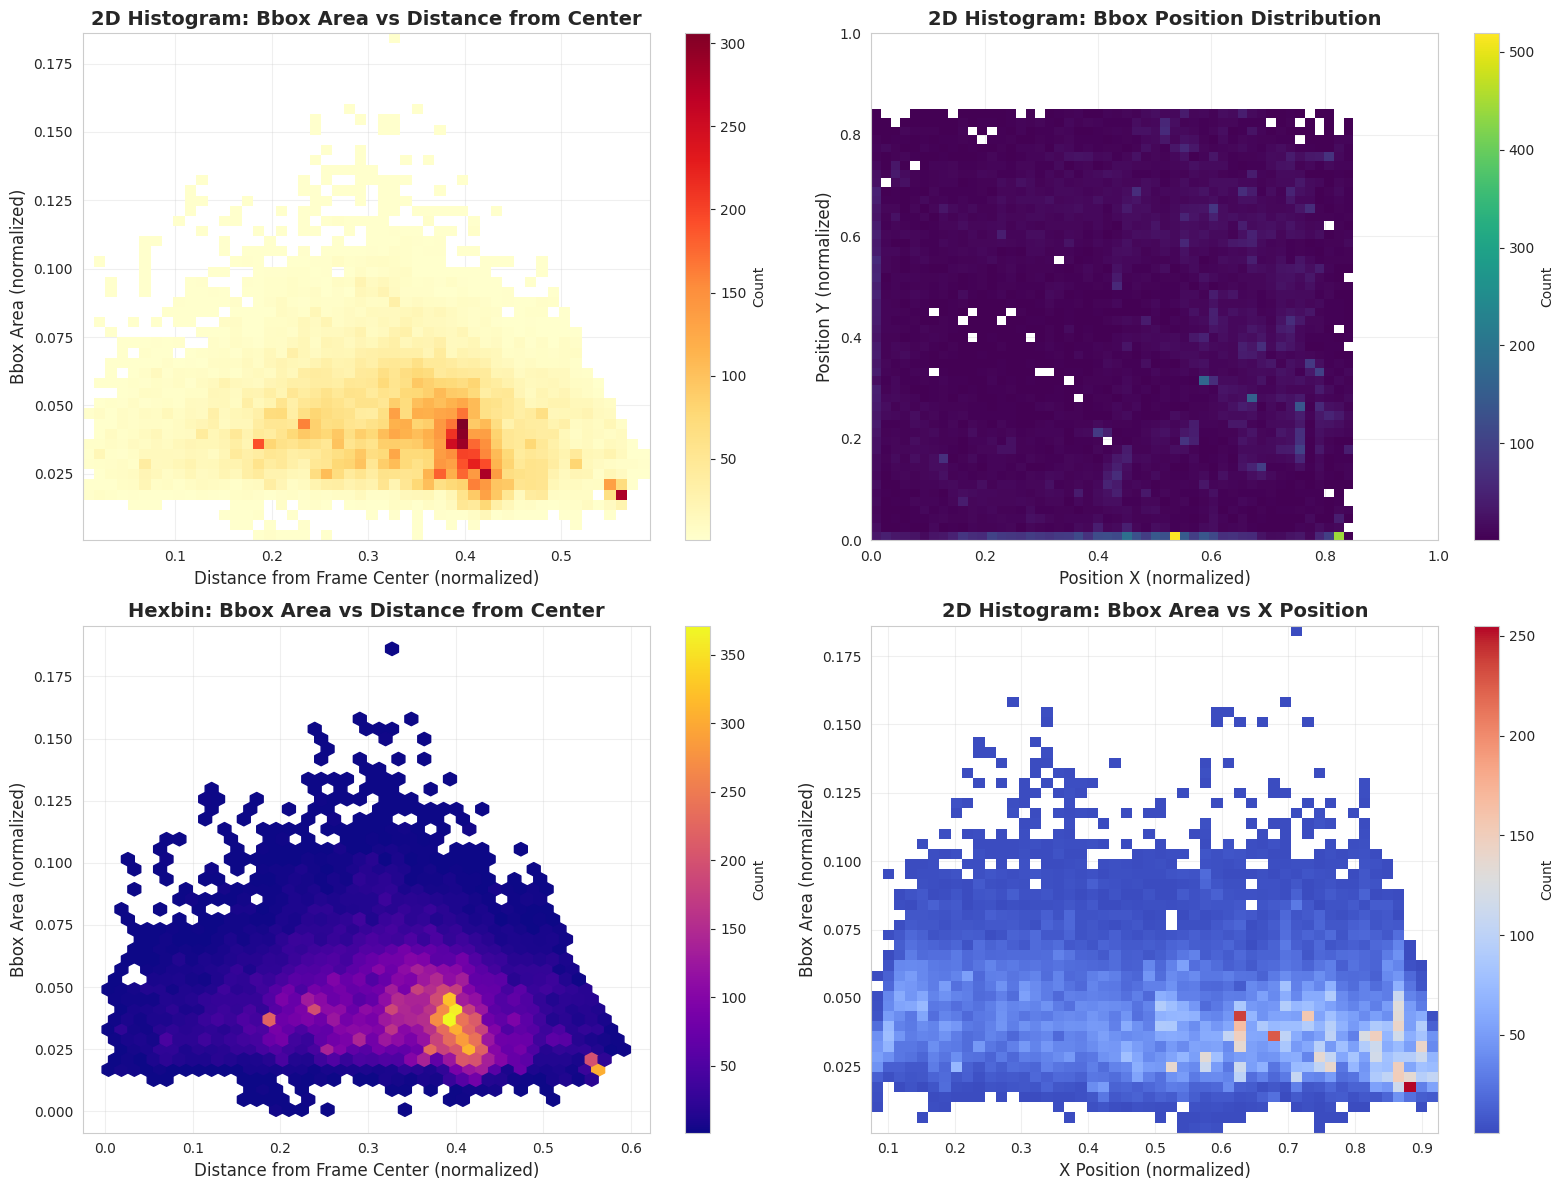

In [19]:
fig = plt.figure(figsize=(16, 12))

# 2D histogram: bbox area vs distance from center
plt.subplot(2, 2, 1)
plt.hist2d(df['dist_from_center'], df['bbox_area'], bins=50, cmap='YlOrRd', cmin=1)
plt.colorbar(label='Count')
plt.xlabel('Distance from Frame Center (normalized)', fontsize=12)
plt.ylabel('Bbox Area (normalized)', fontsize=12)
plt.title('2D Histogram: Bbox Area vs Distance from Center', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

# 2D histogram: pos_x vs pos_y
plt.subplot(2, 2, 2)
plt.hist2d(df['pos_x'], df['pos_y'], bins=50, cmap='viridis', cmin=1)
plt.colorbar(label='Count')
plt.xlabel('Position X (normalized)', fontsize=12)
plt.ylabel('Position Y (normalized)', fontsize=12)
plt.title('2D Histogram: Bbox Position Distribution', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1)

# Scatter plot with hexbin: distance from center vs bbox area
plt.subplot(2, 2, 3)
plt.hexbin(df['dist_from_center'], df['bbox_area'], gridsize=40, cmap='plasma', mincnt=1)
plt.colorbar(label='Count')
plt.xlabel('Distance from Frame Center (normalized)', fontsize=12)
plt.ylabel('Bbox Area (normalized)', fontsize=12)
plt.title('Hexbin: Bbox Area vs Distance from Center', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

# 2D histogram: x position vs bbox area
plt.subplot(2, 2, 4)
plt.hist2d(df['x'], df['bbox_area'], bins=50, cmap='coolwarm', cmin=1)
plt.colorbar(label='Count')
plt.xlabel('X Position (normalized)', fontsize=12)
plt.ylabel('Bbox Area (normalized)', fontsize=12)
plt.title('2D Histogram: Bbox Area vs X Position', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bbox_position_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Additional Analysis: Correlation Heatmap

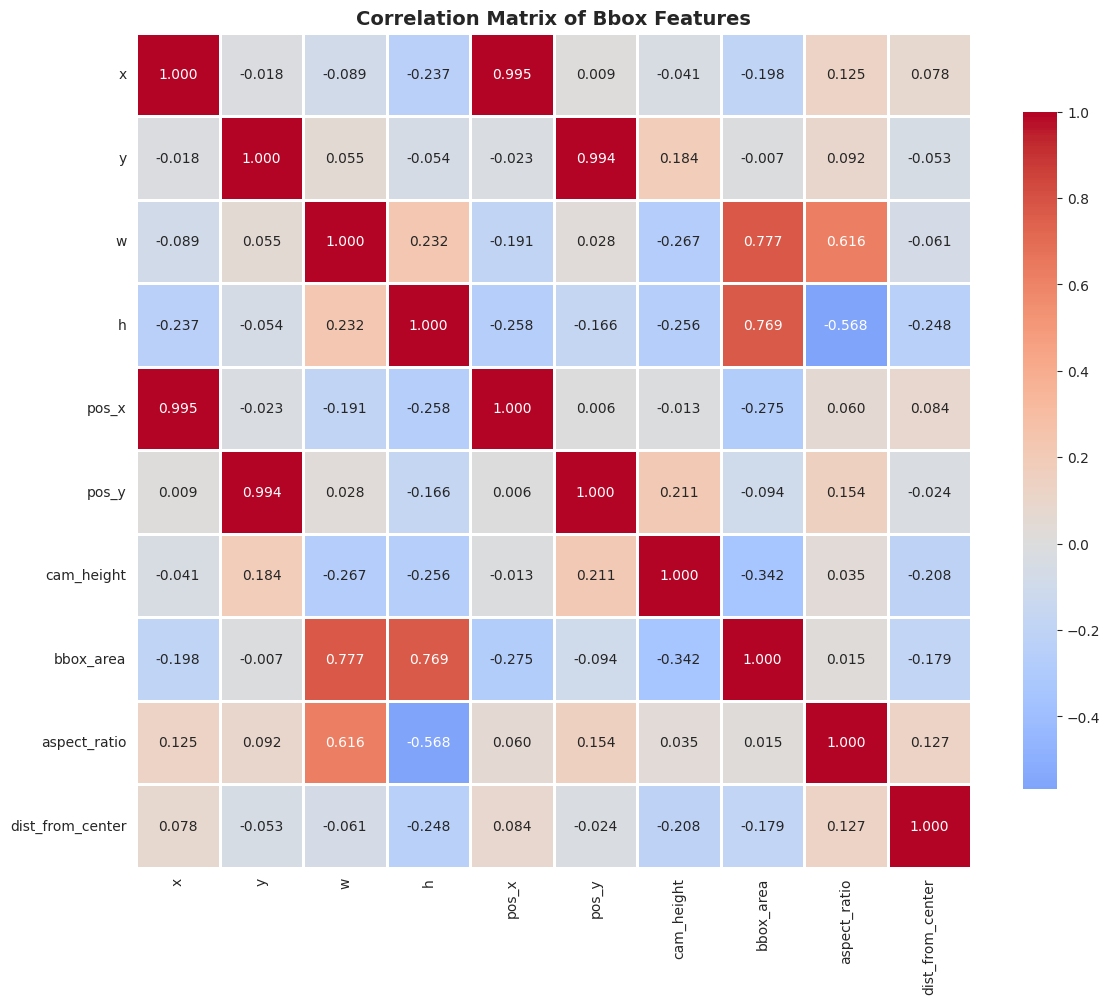

In [20]:
# Correlation analysis
numeric_cols = ['x', 'y', 'w', 'h', 'pos_x', 'pos_y', 'cam_height', 'bbox_area', 'aspect_ratio', 'dist_from_center']
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Bbox Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Summary Statistics

In [21]:
print("="*60)
print("DATASET SUMMARY")
print("="*60)

print(f"\nTotal annotations: {len(df):,}")
print(f"Unique files: {df['filename'].nunique():,}")

print("\n" + "-"*60)
print("Distribution by subset:")
print("-"*60)
for subset in sorted(df['subset'].unique()):
    count = len(df[df['subset'] == subset])
    pct = count / len(df) * 100
    print(f"{subset:15s}: {count:6,} boxes ({pct:5.2f}%)")

print("\n" + "-"*60)
print("Camera height statistics:")
print("-"*60)
print(f"Unique heights: {df['cam_height'].nunique()}")
print(f"Range: {df['cam_height'].min()} - {df['cam_height'].max()} cm")
print(f"Mean: {df['cam_height'].mean():.1f} cm")
print(f"Std: {df['cam_height'].std():.1f} cm")

print("\n" + "-"*60)
print("Bbox area statistics:")
print("-"*60)
print(f"Mean: {df['bbox_area'].mean():.4f}")
print(f"Median: {df['bbox_area'].median():.4f}")
print(f"Std: {df['bbox_area'].std():.4f}")
print(f"Min: {df['bbox_area'].min():.4f}")
print(f"Max: {df['bbox_area'].max():.4f}")

print("\n" + "-"*60)
print("Bbox aspect ratio statistics:")
print("-"*60)
print(f"Mean: {df['aspect_ratio'].mean():.4f}")
print(f"Median: {df['aspect_ratio'].median():.4f}")
print(f"Std: {df['aspect_ratio'].std():.4f}")
print(f"Min: {df['aspect_ratio'].min():.4f}")
print(f"Max: {df['aspect_ratio'].max():.4f}")
print(f"Wider than tall (>1): {(df['aspect_ratio'] > 1).sum()} ({(df['aspect_ratio'] > 1).sum()/len(df)*100:.2f}%)")
print(f"Taller than wide (<1): {(df['aspect_ratio'] < 1).sum()} ({(df['aspect_ratio'] < 1).sum()/len(df)*100:.2f}%)")

print("\n" + "-"*60)
print("Distance from center statistics:")
print("-"*60)
print(f"Mean: {df['dist_from_center'].mean():.4f}")
print(f"Median: {df['dist_from_center'].median():.4f}")
print(f"Std: {df['dist_from_center'].std():.4f}")

print("\n" + "="*60)

DATASET SUMMARY

Total annotations: 31,252
Unique files: 7,301

------------------------------------------------------------
Distribution by subset:
------------------------------------------------------------
holdout        :    407 boxes ( 1.30%)
holdout_v2     :    609 boxes ( 1.95%)
train          : 27,192 boxes (87.01%)
val            :  3,044 boxes ( 9.74%)

------------------------------------------------------------
Camera height statistics:
------------------------------------------------------------
Unique heights: 12
Range: 220 - 340 cm
Mean: 265.5 cm
Std: 27.7 cm

------------------------------------------------------------
Bbox area statistics:
------------------------------------------------------------
Mean: 0.0425
Median: 0.0397
Std: 0.0179
Min: 0.0007
Max: 0.1861

------------------------------------------------------------
Bbox aspect ratio statistics:
------------------------------------------------------------
Mean: 0.8636
Median: 0.8096
Std: 0.2902
Min: 0.2361
Max: